IMPORTANDO OS DADOS


In [ ]:
import pandas as pd

nomes = ['num_identificacao', 'diagnostico', 'raio_media', 'textura_media', 'perimetro_media', 'area_media', 'suavidade_media', 'compacidade_media', 'concavidade_media', 'pontos_concavos_media', 'simetria_media', 'dimensao_fractal_media', 'raio_se', 'textura_se', 'perimetro_se', 'area_se', 'suavidade_se', 'compacidade_se', 'concavidade_se', 'pontos_concavos_se', 'simetria_se', 'dimensao_fractal_se', 'raio_worst', 'textura_worst', 'perimetro_worst', 'area_worst', 'suavidade_worst', 'compacidade_worst', 'concavidade_worst', 'pontos_concavos_worst', 'simetria_worst', 'dimensao_fractal_worst']

df = pd.read_csv('wdbc.data', header=None, names=nomes)

EDA

In [2]:
df.head()

,num_identificacao,diagnostico,raio_media,textura_media,perimetro_media,area_media,suavidade_media,compacidade_media,concavidade_media,pontos_concavos_media,...,raio_worst,textura_worst,perimetro_worst,area_worst,suavidade_worst,compacidade_worst,concavidade_worst,pontos_concavos_worst,simetria_worst,dimensao_fractal_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   num_identificacao       569 non-null    int64  
 1   diagnostico             569 non-null    str    
 2   raio_media              569 non-null    float64
 3   textura_media           569 non-null    float64
 4   perimetro_media         569 non-null    float64
 5   area_media              569 non-null    float64
 6   suavidade_media         569 non-null    float64
 7   compacidade_media       569 non-null    float64
 8   concavidade_media       569 non-null    float64
 9   pontos_concavos_media   569 non-null    float64
 10  simetria_media          569 non-null    float64
 11  dimensao_fractal_media  569 non-null    float64
 12  raio_se                 569 non-null    float64
 13  textura_se              569 non-null    float64
 14  perimetro_se            569 non-null    float64
 15  

In [4]:
df['diagnostico'].value_counts()

diagnostico
B    357
M    212
Name: count, dtype: int64

LIMPANDO E PADRONIZANDO A VARIAVEL X

In [5]:
df.drop(['num_identificacao'], axis=1, inplace=True)

In [6]:
df['diagnostico'] = df['diagnostico'].map({'M': 1, 'B': 0})

In [7]:
df['diagnostico'].value_counts()

diagnostico
0    357
1    212
Name: count, dtype: int64

VISUALIZANDO A OCORRENCIA DO DIAGNOSTICOS


In [8]:
y = df['diagnostico']

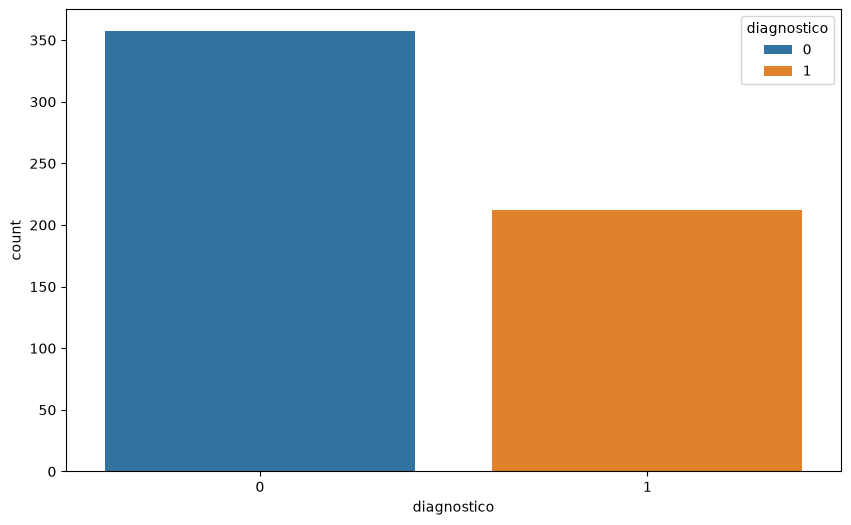

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.countplot(x='diagnostico', data=df, hue=y)
plt.xticks()
plt.show()

SEPARANDO AS VARIAVEIS DE TREINO E TESTE

In [10]:
X = df.drop('diagnostico', axis=1)
y = df['diagnostico']


from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# LOGISTIC REGRESSION
CRIANDO O PRIMEIRO MODELO E TREINANDO O MODELO

In [11]:
from sklearn.linear_model import LogisticRegression

modelo = LogisticRegression(max_iter=1000, random_state=42)
modelo.fit(X_train, y_train)

c:\Users\nimgu\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

FAZENDO A PREDIÇÃO DO MODELO LOGISTIC

In [12]:
y_pred = modelo.predict(X_test)

DESEMPENHO DO MODELO

In [13]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Acurácia:", accuracy_score(y_test, y_pred))
print("\nRelatório de Classificação:")
print(classification_report(y_test, y_pred))
print("\nMatriz de Confusão:")
print(confusion_matrix(y_test, y_pred))

Acurácia: 0.9649122807017544

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.96      0.98      0.97       108
           1       0.97      0.94      0.95        63

    accuracy                           0.96       171
   macro avg       0.97      0.96      0.96       171
weighted avg       0.96      0.96      0.96       171


Matriz de Confusão:
[[106   2]
 [  4  59]]


CURVA ROC - VISUALIZANDO A TAXA TPR E FPR

ROC AUC:  0.9978


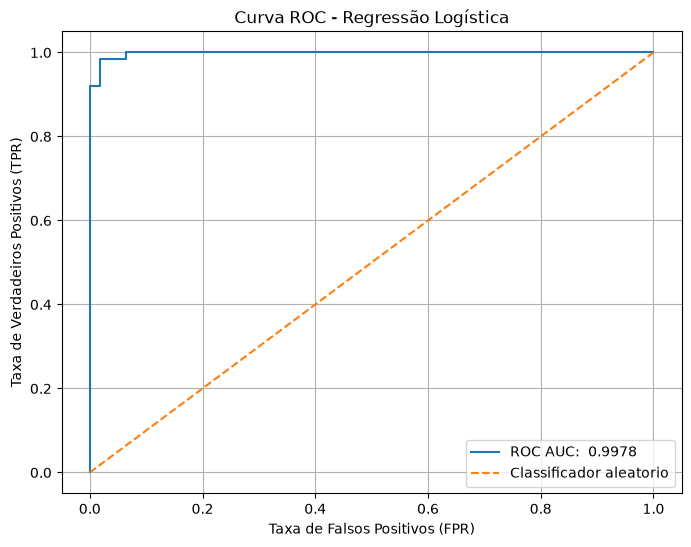

In [14]:
from sklearn.metrics import roc_curve, roc_auc_score
y_prob = modelo.predict_proba(X_test)[:,1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

auc = roc_auc_score(y_test, y_prob)

print(f'ROC AUC: {auc: .4f}')

plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f'ROC AUC: {auc: .4f}')
plt.plot([0, 1], [0, 1], '--', label = 'Classificador aleatorio')
plt.xlabel('Taxa de Falsos Positivos (FPR)')
plt.ylabel('Taxa de Verdadeiros Positivos (TPR)')
plt.title('Curva ROC - Regressão Logística')
plt.legend()
plt.grid(True)
plt.show()

COEFICIENTE DAS VARIAVEIS

In [15]:
coeficientes = pd.DataFrame({
    'Variavel': X.columns,
    'Coeficiente': modelo.coef_[0]
})

coeficientes['Coeficiente_Absoluto'] = coeficientes['Coeficiente'].abs()

coeficientes = coeficientes.sort_values(
    by='Coeficiente_Absoluto',
    ascending=False
)

print(coeficientes)

                  Variavel  Coeficiente  Coeficiente_Absoluto
0               raio_media    -2.164499              2.164499
26       concavidade_worst     1.609608              1.609608
11              textura_se    -1.576946              1.576946
25       compacidade_worst     1.131797              1.131797
20              raio_worst    -1.074072              1.074072
28          simetria_worst     0.768755              0.768755
6        concavidade_media     0.666760              0.666760
27   pontos_concavos_worst     0.644362              0.644362
5        compacidade_media     0.407625              0.407625
21           textura_worst     0.406703              0.406703
7    pontos_concavos_media     0.365725              0.365725
24         suavidade_worst     0.259431              0.259431
12            perimetro_se    -0.239055              0.239055
8           simetria_media     0.211632              0.211632
1            textura_media    -0.173496              0.173496
4       

VISUALIZANDO A IMPORTANCIA DAS 10 VARIAVEIS DE ACORDO COM SUA COEFIENCIA

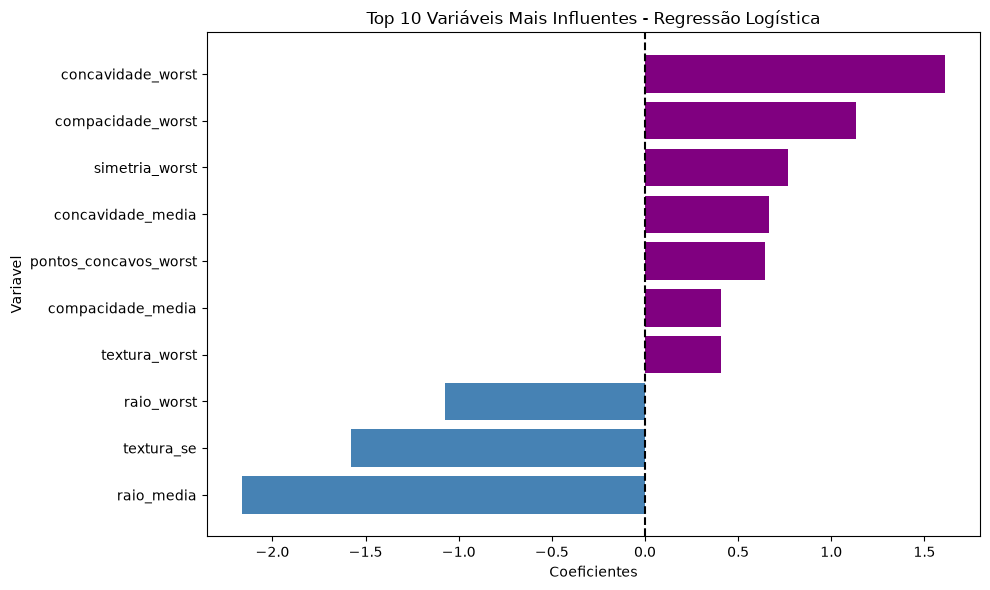

In [16]:
coef_df = pd.DataFrame({
    'Variavel': X.columns,
    'Coeficiente': modelo.coef_[0]
})

coef_df['Coeficiente_Absoluto'] = coef_df['Coeficiente'].abs()

top10 = coef_df.sort_values(
    by='Coeficiente_Absoluto',
    ascending=False
).head(10)


top10 = top10.sort_values(by='Coeficiente')

positivos = top10['Coeficiente'] > 0

plt.figure(figsize=(10, 6))

plt.barh(
    top10['Variavel'],
    top10['Coeficiente'],
    color=['purple' if x > 0 else 'steelblue'
           for x in top10['Coeficiente']]
)

plt.axvline(0, color='black', linestyle = '--')

plt.xlabel('Coeficientes')
plt.ylabel('Variavel')
plt.title('Top 10 Variáveis Mais Influentes - Regressão Logística')

plt.tight_layout()
plt.show()

In [17]:
coef_df

,Variavel,Coeficiente,Coeficiente_Absoluto
0,raio_media,-2.164499,2.164499
1,textura_media,-0.173496,0.173496
2,perimetro_media,0.136309,0.136309
3,area_media,0.003992,0.003992
4,suavidade_media,0.137994,0.137994
5,compacidade_media,0.407625,0.407625
6,concavidade_media,0.666760,0.666760
7,pontos_concavos_media,0.365725,0.365725
8,simetria_media,0.211632,0.211632
9,dimensao_fractal_media,0.028713,0.028713


# RANDOM FOREST CLASSIFIER

TREINANDO O SEGUNDO MODELO

In [18]:
from sklearn.ensemble import RandomForestClassifier

modelo_rf = RandomForestClassifier(n_estimators=300, 
                                   random_state=42,
                                   )

modelo_rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

PREDICAO DO MODELO

In [19]:
y_pred_rf = modelo.predict(X_test)

DESEMPENHO DO MODELO RANDOM FOREST CLASSIFIER

Acuracia: 0.9649122807017544
Relatorio de Classificacao
              precision    recall  f1-score   support

           0       0.96      0.98      0.97       108
           1       0.97      0.94      0.95        63

    accuracy                           0.96       171
   macro avg       0.97      0.96      0.96       171
weighted avg       0.96      0.96      0.96       171

Matriz de Confusao
[[106   2]
 [  4  59]]


Text(0.5, 1.0, 'Matriz de Confusao - Random Forest')

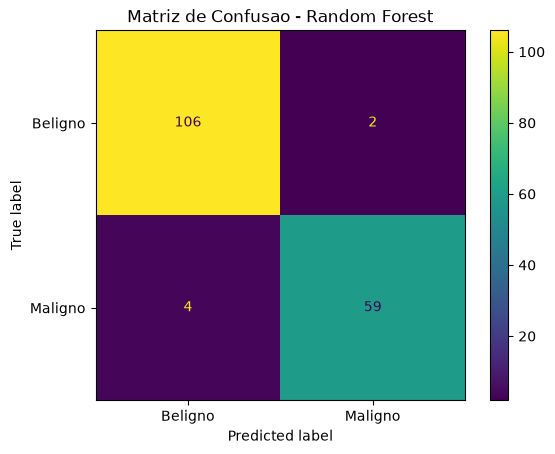

In [20]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

acuracia_rf = accuracy_score(y_test, y_pred_rf)

print(f'Acuracia: {acuracia_rf}')


print('Relatorio de Classificacao')
print(classification_report(y_test, y_pred_rf))



cm_rf = confusion_matrix(y_test, y_pred_rf)

print("Matriz de Confusao")
print(cm_rf)


disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=['Beligno', 'Maligno']
)

disp.plot()
plt.title("Matriz de Confusao - Random Forest")

CURVA ROC

ROC-AUC: 0.9971


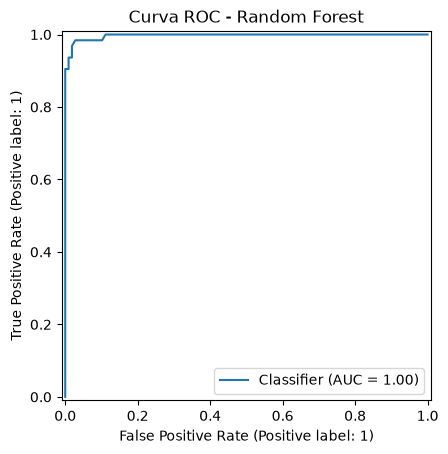

In [21]:
from sklearn.metrics import roc_auc_score, RocCurveDisplay

y_prob_rf = modelo_rf.predict_proba(X_test)[:, 1]

roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

print(f"ROC-AUC: {roc_auc_rf:.4f}")

RocCurveDisplay.from_predictions(y_test, y_prob_rf)
plt.title("Curva ROC - Random Forest")
plt.show()

VARIAVEIS MAIS INFLUENCIARAM ESSE DESEMPENHO

In [ ]:
importancias = pd.DataFrame({
    "Variavel": X_train.columns,
    "Importancia": modelo_rf.feature_importances_
})

importancias = importancias.sort_values(
    by="Importancia",
    ascending=False
)

print(importancias.head(10))

                 Variavel  Importancia
27  pontos_concavos_worst     0.135463
7   pontos_concavos_media     0.128914
23             area_worst     0.127008
22        perimetro_worst     0.110301
20             raio_worst     0.066481
6       concavidade_media     0.059586
2         perimetro_media     0.046943
0              raio_media     0.043909
26      concavidade_worst     0.040895
3              area_media     0.038523


TOP 10 VARIAVEIS FLUENTES

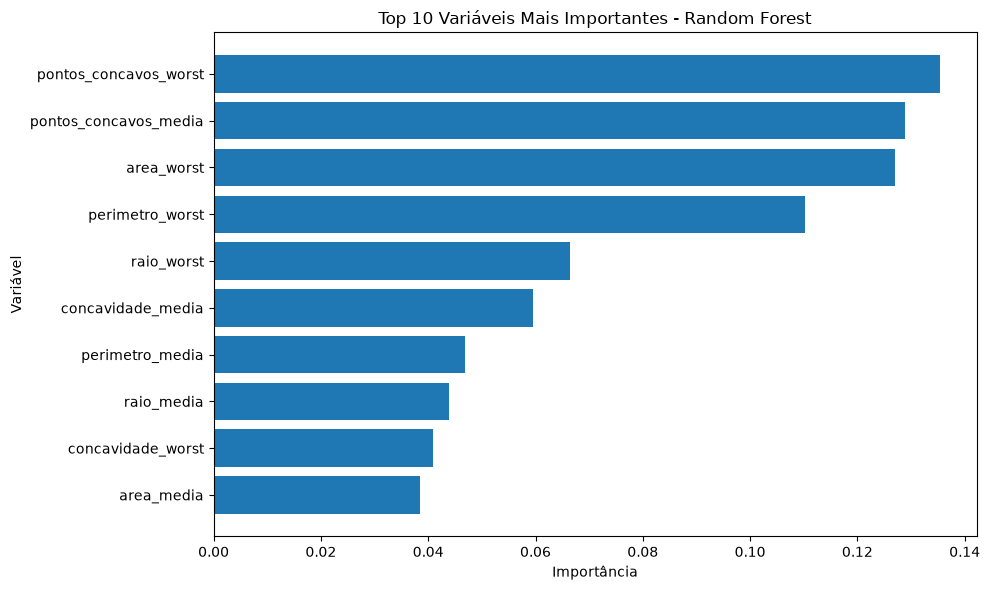

In [23]:
top10 = importancias.head(10).sort_values("Importancia")

plt.figure(figsize=(10, 6))

plt.barh(
    top10["Variavel"],
    top10["Importancia"]
)

plt.xlabel("Importância")
plt.ylabel("Variável")
plt.title("Top 10 Variáveis Mais Importantes - Random Forest")

plt.tight_layout()
plt.show()

VARIAVEIS IMPORTANTES

In [24]:
modelo_rf.feature_importances_

array([0.04390925, 0.01210396, 0.0469429 , 0.03852279, 0.00566539,
       0.01261847, 0.05958617, 0.12891432, 0.004424  , 0.00464225,
       0.01944147, 0.00399474, 0.00920974, 0.02897834, 0.00551634,
       0.00544225, 0.00595846, 0.00464684, 0.00424255, 0.00623142,
       0.06648084, 0.02025168, 0.11030058, 0.12700834, 0.01105351,
       0.01731353, 0.04089527, 0.13546345, 0.01394075, 0.00630042])

# XGBOOST

TREINANDO O TERCEIRO MODELO

In [25]:
from xgboost import XGBClassifier

from xgboost import XGBClassifier

modelo_xgb = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    random_state=42,
    eval_metric='logloss'
)

modelo_xgb.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


PREDICAO DO MODELO

In [26]:
y_pred_xgb = modelo_xgb.predict(X_test)

DESEMPENHO DO MODELO

In [27]:
from sklearn.metrics import accuracy_score, classification_report

acuracia_xgb = accuracy_score(y_test, y_pred_xgb)

print(f"Acurácia: {acuracia_xgb:.4f}")

print("\nRelatório de Classificação:")
print(classification_report(y_test, y_pred_xgb))

Acurácia: 0.9591

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.96      0.97      0.97       108
           1       0.95      0.94      0.94        63

    accuracy                           0.96       171
   macro avg       0.96      0.95      0.96       171
weighted avg       0.96      0.96      0.96       171



MATRIZ DE CONFUSAO

Matriz de Confusão:
[[105   3]
 [  4  59]]


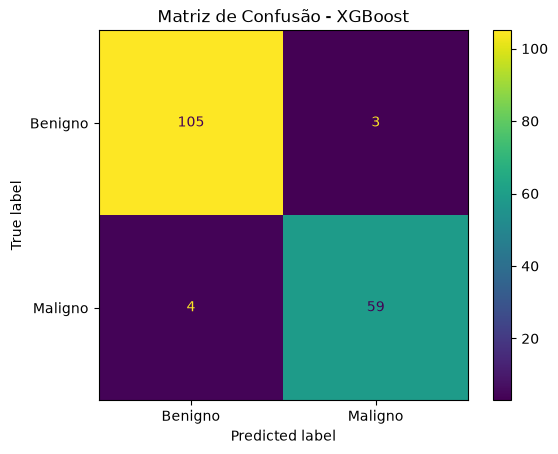

In [28]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_xgb = confusion_matrix(y_test, y_pred_xgb)

print("Matriz de Confusão:")
print(cm_xgb)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=["Benigno", "Maligno"]
)

disp.plot()
plt.title("Matriz de Confusão - XGBoost")
plt.show()

CURVA ROC

ROC-AUC: 0.9953


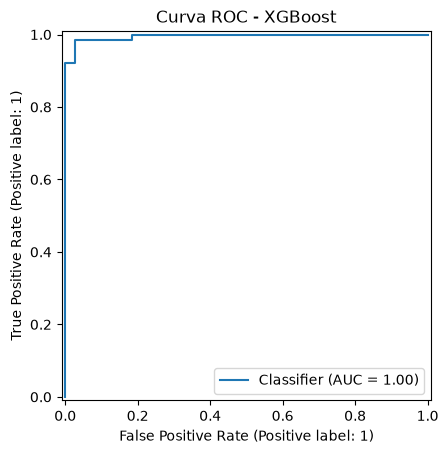

In [29]:
from sklearn.metrics import roc_auc_score, RocCurveDisplay

y_prob_xgb = modelo_xgb.predict_proba(X_test)[:, 1]

roc_auc_xgb = roc_auc_score(y_test, y_prob_xgb)

print(f"ROC-AUC: {roc_auc_xgb:.4f}")

RocCurveDisplay.from_predictions(y_test, y_prob_xgb)
plt.title("Curva ROC - XGBoost")
plt.show()

VARIAVEIS MAIS IMPORTANTES DE ACORDO COM O MODELO

In [ ]:
importancias_xgb = pd.DataFrame({
    "Variavel": X_train.columns,
    "Importancia": modelo_xgb.feature_importances_
})

importancias_xgb = importancias_xgb.sort_values(
    by="Importancia",
    ascending=False
)

print(importancias_xgb.head(10))

                 Variavel  Importancia
7   pontos_concavos_media     0.443218
27  pontos_concavos_worst     0.115592
22        perimetro_worst     0.081958
20             raio_worst     0.053695
21          textura_worst     0.029332
23             area_worst     0.028735
26      concavidade_worst     0.027132
1           textura_media     0.022326
12           perimetro_se     0.022106
16         concavidade_se     0.020937


## VALIDAÇÃO CRUZADA

In [31]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [32]:
scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc'
}

In [33]:
resultado_lr = cross_validate(
    modelo,
    X,
    y,
    cv=cv,
    scoring=scoring
)

c:\Users\nimgu\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\nimgu\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://s

In [34]:
resultado_rf = cross_validate(
    modelo_rf,
    X,
    y,
    cv=cv,
    scoring=scoring
)

In [35]:
resultado_xgb = cross_validate(
    modelo_xgb,
    X,
    y,
    cv=cv,
    scoring=scoring
)

In [36]:
def mostrar_resultados(nome, resultado):

    print(f"\n===== {nome} =====")

    for metrica in scoring.keys():

        valores = resultado[f'test_{metrica}']

        print(
            f"{metrica.upper()}: "
            f"{valores.mean():.4f} "
            f"(± {valores.std():.4f})"
        )

In [37]:
mostrar_resultados("Logistic Regression", resultado_lr)
mostrar_resultados("Random Forest", resultado_rf)
mostrar_resultados("XGBoost", resultado_xgb)


===== Logistic Regression =====
ACCURACY: 0.9473 (± 0.0146)
PRECISION: 0.9484 (± 0.0354)
RECALL: 0.9105 (± 0.0425)
F1: 0.9278 (± 0.0207)
ROC_AUC: 0.9932 (± 0.0051)

===== Random Forest =====
ACCURACY: 0.9526 (± 0.0131)
PRECISION: 0.9461 (± 0.0389)
RECALL: 0.9295 (± 0.0572)
F1: 0.9355 (± 0.0194)
ROC_AUC: 0.9895 (± 0.0077)

===== XGBoost =====
ACCURACY: 0.9613 (± 0.0142)
PRECISION: 0.9588 (± 0.0326)
RECALL: 0.9389 (± 0.0480)
F1: 0.9473 (± 0.0202)
ROC_AUC: 0.9936 (± 0.0043)


In [38]:
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate

# ============================================================
# 1. Modelo XGBoost
# ============================================================

xgb = XGBClassifier(
    random_state=42,
    eval_metric='logloss'
)

# ============================================================
# 2. Hiperparâmetros que serão testados
# ============================================================

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [2, 3, 4],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

# ============================================================
# 3. Cross-Validation estratificada
# ============================================================

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# ============================================================
# 4. GridSearchCV
#    Como 1 = maligno, vamos priorizar o RECALL
# ============================================================

grid_search = GridSearchCV(
    estimator=xgb,
    param_grid=param_grid,
    scoring='recall',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

# ============================================================
# 5. Treinamento
# ============================================================

grid_search.fit(X, y)

# ============================================================
# 6. Melhores parâmetros
# ============================================================

print("\n==============================")
print("MELHORES PARÂMETROS")
print("==============================")

print(grid_search.best_params_)

print("\nMelhor Recall encontrado:")
print(f"{grid_search.best_score_:.4f}")

# ============================================================
# 7. Melhor modelo
# ============================================================

modelo_xgb_otimizado = grid_search.best_estimator_

# ============================================================
# 8. Avaliação completa do modelo otimizado
# ============================================================

scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc'
}

resultado_otimizado = cross_validate(
    modelo_xgb_otimizado,
    X,
    y,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

# ============================================================
# 9. Resultados
# ============================================================

print("\n==============================")
print("XGBOOST OTIMIZADO")
print("==============================")

for metrica in scoring.keys():

    valores = resultado_otimizado[f'test_{metrica}']

    media = valores.mean()
    desvio = valores.std()

    print(
        f"{metrica.upper():10s}: "
        f"{media:.4f} (± {desvio:.4f})"
    )

Fitting 5 folds for each of 108 candidates, totalling 540 fits

MELHORES PARÂMETROS
{'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 300, 'subsample': 0.8}

Melhor Recall encontrado:
0.9576

XGBOOST OTIMIZADO
ACCURACY  : 0.9719 (± 0.0116)
PRECISION : 0.9672 (± 0.0170)
RECALL    : 0.9576 (± 0.0375)
F1        : 0.9618 (± 0.0163)
ROC_AUC   : 0.9943 (± 0.0053)


# VALIDACAO CRUZADA ALINHADA COM FATOS REAIS

In [39]:
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate

# ============================================================
# 1. Modelo XGBoost
# ============================================================

xgb = XGBClassifier(
    random_state=42,
    eval_metric='logloss'
)

# ============================================================
# 2. Hiperparâmetros
# ============================================================

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [2, 3, 4],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

# ============================================================
# 3. INNER CV
#    Usada SOMENTE para encontrar os melhores parâmetros
# ============================================================

inner_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=xgb,
    param_grid=param_grid,
    scoring='recall',
    cv=inner_cv,
    n_jobs=-1
)

# ============================================================
# 4. OUTER CV
#    Usada para avaliar o desempenho do modelo
# ============================================================

outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=123
)

# ============================================================
# 5. Métricas
# ============================================================

scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc'
}

# ============================================================
# 6. Nested Cross-Validation
# ============================================================

resultado_nested = cross_validate(
    grid_search,
    X,
    y,
    cv=outer_cv,
    scoring=scoring,
    n_jobs=-1,
    return_estimator=True
)

# ============================================================
# 7. Resultados
# ============================================================

print("\n==========================================")
print("NESTED CROSS-VALIDATION - XGBOOST")
print("==========================================")

for metrica in scoring.keys():

    valores = resultado_nested[f'test_{metrica}']

    print(
        f"{metrica.upper():10s}: "
        f"{valores.mean():.4f} "
        f"(± {valores.std():.4f})"
    )

# ============================================================
# 8. Melhores parâmetros encontrados em cada fold
# ============================================================

print("\n==========================================")
print("MELHORES PARÂMETROS POR FOLD")
print("==========================================")

for i, modelo in enumerate(resultado_nested['estimator'], start=1):

    print(f"\nFold {i}:")
    print(modelo.best_params_)
    print(f"Recall interno: {modelo.best_score_:.4f}")


NESTED CROSS-VALIDATION - XGBOOST
ACCURACY  : 0.9684 (± 0.0219)
PRECISION : 0.9625 (± 0.0319)
RECALL    : 0.9532 (± 0.0292)
F1        : 0.9577 (± 0.0291)
ROC_AUC   : 0.9934 (± 0.0072)

MELHORES PARÂMETROS POR FOLD

Fold 1:
{'colsample_bytree': 0.8, 'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 200, 'subsample': 0.8}
Recall interno: 0.9406

Fold 2:
{'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 300, 'subsample': 0.8}
Recall interno: 0.9706

Fold 3:
{'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.8}
Recall interno: 0.9529

Fold 4:
{'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 300, 'subsample': 0.8}
Recall interno: 0.9529

Fold 5:
{'colsample_bytree': 1.0, 'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 300, 'subsample': 0.8}
Recall interno: 0.9471


UTILIZANDO O SHAPE EXPLAINER PARA IDENTIFICAR AS CARACTERISTICAS DA INFLUENCIA DAS VARIAVEIS AO DIAGNOSTICOS

c:\Users\nimgu\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


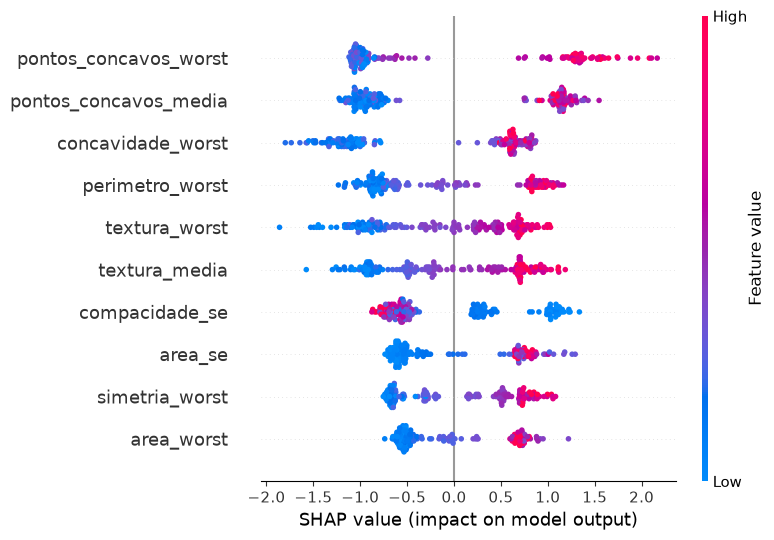

In [ ]:
import shap
import matplotlib.pyplot as plt

# ============================================================
# 1. Modelo XGBoost otimizado

modelo_xgb_otimizado = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric='logloss'
)

# Treinar
modelo_xgb_otimizado.fit(X_train, y_train)

# ============================================================
# 2. Criar o SHAP Explainer

explainer = shap.TreeExplainer(modelo_xgb_otimizado)

shap_values = explainer.shap_values(X_test)

# ============================================================
# 3. SHAP Summary Plot

shap.summary_plot(
    shap_values,
    X_test,
    max_display=10
)


VARIAVEIS MAIS IMPORTANTES E SEUS RESPESCTIVOS COEFICIENTES DE ACORDO COM O SHAP

In [41]:
import pandas as pd
import numpy as np

importancia_shap = pd.DataFrame({
    'Variavel': X_test.columns,
    'Importancia_SHAP': np.abs(shap_values).mean(axis=0)
})

importancia_shap = importancia_shap.sort_values(
    by='Importancia_SHAP',
    ascending=False
)

print(importancia_shap.head(10))

                 Variavel  Importancia_SHAP
27  pontos_concavos_worst          1.099600
7   pontos_concavos_media          1.020640
26      concavidade_worst          0.896904
22        perimetro_worst          0.743913
21          textura_worst          0.672585
1           textura_media          0.663552
15         compacidade_se          0.631959
13                area_se          0.621594
28         simetria_worst          0.588881
23             area_worst          0.523541


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter

# ============================================================
# 1. TOP 10 VARIÁVEIS PELO SHAP

importancia_shap = pd.DataFrame({
    "Variavel": X_test.columns,
    "Importancia_SHAP": np.abs(shap_values).mean(axis=0)
}).sort_values(
    "Importancia_SHAP",
    ascending=False
)

top10 = importancia_shap.head(10)["Variavel"].tolist()

indices = [
    X_test.columns.get_loc(col)
    for col in top10
]

X_top = X_test[top10].values
SHAP_top = shap_values[:, indices]

# ============================================================
# 2. CONFIGURAÇÕES

# Número de frames
N_FRAMES = 80

# Quantidade de amostras
n_amostras = len(X_test)

# ------------------------------------------------------------
# Jitter vertical
# Dá o efeito de "nuvem" parecido com o SHAP original
# ------------------------------------------------------------

rng = np.random.default_rng(42)

jitter = rng.normal(
    0,
    0.12,
    size=(n_amostras, len(top10))
)

# ============================================================
# 3. CORES BASEADAS NOS VALORES DAS VARIÁVEIS

cores = np.zeros_like(X_top, dtype=float)

for i in range(len(top10)):

    minimo = X_top[:, i].min()
    maximo = X_top[:, i].max()

    if maximo != minimo:
        cores[:, i] = (
            (X_top[:, i] - minimo) /
            (maximo - minimo)
        )

# ============================================================
# 4. LIMITES DO GRÁFICO


limite = np.max(np.abs(SHAP_top)) * 1.15

# ============================================================
# 5. FIGURA
# ============================================================

fig, ax = plt.subplots(
    figsize=(13, 8)
)

# ============================================================
# 6. FUNÇÃO DA ANIMAÇÃO
# ============================================================

def atualizar(frame):

    ax.clear()

    # --------------------------------------------------------
    # Progresso da animação
    # 0 → todos começam no centro
    # 1 → todos chegam aos valores reais
    # --------------------------------------------------------

    progresso = frame / (N_FRAMES - 1)

    # Suavização para movimento mais natural
    progresso_suave = (
        3 * progresso**2
        - 2 * progresso**3
    )

    for i in range(len(top10)):

        # ----------------------------------------------------
        # SHAP começa em 0 e vai até o valor real
        # ----------------------------------------------------

        shap_atual = (
            SHAP_top[:, i]
            * progresso_suave
        )

        # ----------------------------------------------------
        # Jitter também aparece gradualmente
        # ----------------------------------------------------

        jitter_atual = (
            jitter[:, i]
            * progresso_suave
        )

        y = (
            i
            + jitter_atual
        )

        # ----------------------------------------------------
        # Cor aparece gradualmente
        # ----------------------------------------------------

        cor_atual = (
            cores[:, i]
            * progresso_suave
            + 0.5 * (1 - progresso_suave)
        )

        ax.scatter(
            shap_atual,
            y,
            c=cor_atual,
            cmap=shap.plots.colors.red_blue,
            vmin=0,
            vmax=1,
            s=30,
            alpha=0.70,
            edgecolors="none"
        )

    # ========================================================
    # LINHA CENTRAL
    # ========================================================

    ax.axvline(
        0,
        linestyle="--",
        linewidth=1,
        alpha=0.6
    )

    # ========================================================
    # EIXOS
    # ========================================================

    ax.set_xlim(
        -limite,
        limite
    )

    ax.set_ylim(
        -0.7,
        len(top10) - 0.3
    )

    ax.set_yticks(
        range(len(top10))
    )

    ax.set_yticklabels(
        top10
    )

    ax.invert_yaxis()

    ax.set_xlabel(
        "Impacto SHAP →"
    )

    ax.set_ylabel(
        ""
    )

    # ========================================================
    # TÍTULO
    # ========================================================

    ax.set_title(
        "XGBoost + SHAP — Evolução das principais variáveis",
        fontsize=16,
        fontweight="bold"
    )

    # ========================================================
    # LEGENDA TEXTUAL
    # ========================================================

    ax.text(
        0.01,
        -0.08,
        "← Menor tendência para maligno",
        transform=ax.transAxes,
        fontsize=10
    )

    ax.text(
        0.72,
        -0.08,
        "Maior tendência para maligno →",
        transform=ax.transAxes,
        fontsize=10
    )

    # ========================================================
    # PROGRESSO
    # ========================================================

    ax.text(
        0.98,
        1.02,
        f"{int(progresso * 100)}%",
        transform=ax.transAxes,
        ha="right",
        fontsize=11
    )

    ax.grid(
        axis="x",
        alpha=0.15
    )

    plt.tight_layout()


# ============================================================
# 7. CRIAR ANIMAÇÃO
# ============================================================

animacao = FuncAnimation(
    fig,
    atualizar,
    frames=N_FRAMES,
    interval=50,
    repeat=True
)

# ============================================================
# 8. SALVAR MP4
# ============================================================

arquivo = "SHAP_Breast_Cancer_Nuvem.mp4"

writer = FFMpegWriter(
    fps=60,
    bitrate=4000
)

animacao.save(
    "shapp_top10_breast_cancer.gif",
    writer="pillow",
    fps=60
)

plt.close()

print("====================================")
print("ANIMAÇÃO CRIADA!")
print("====================================")
print(f"Arquivo: {arquivo}")

print("\nTOP 10 VARIÁVEIS:")

for i, variavel in enumerate(top10, 1):
    print(f"{i}. {variavel}")

ANIMAÇÃO CRIADA!
Arquivo: SHAP_Breast_Cancer_Nuvem.mp4

TOP 10 VARIÁVEIS:
1. pontos_concavos_worst
2. pontos_concavos_media
3. concavidade_worst
4. perimetro_worst
5. textura_worst
6. textura_media
7. compacidade_se
8. area_se
9. simetria_worst
10. area_worst


# COMPARACAO DOS MODELOS

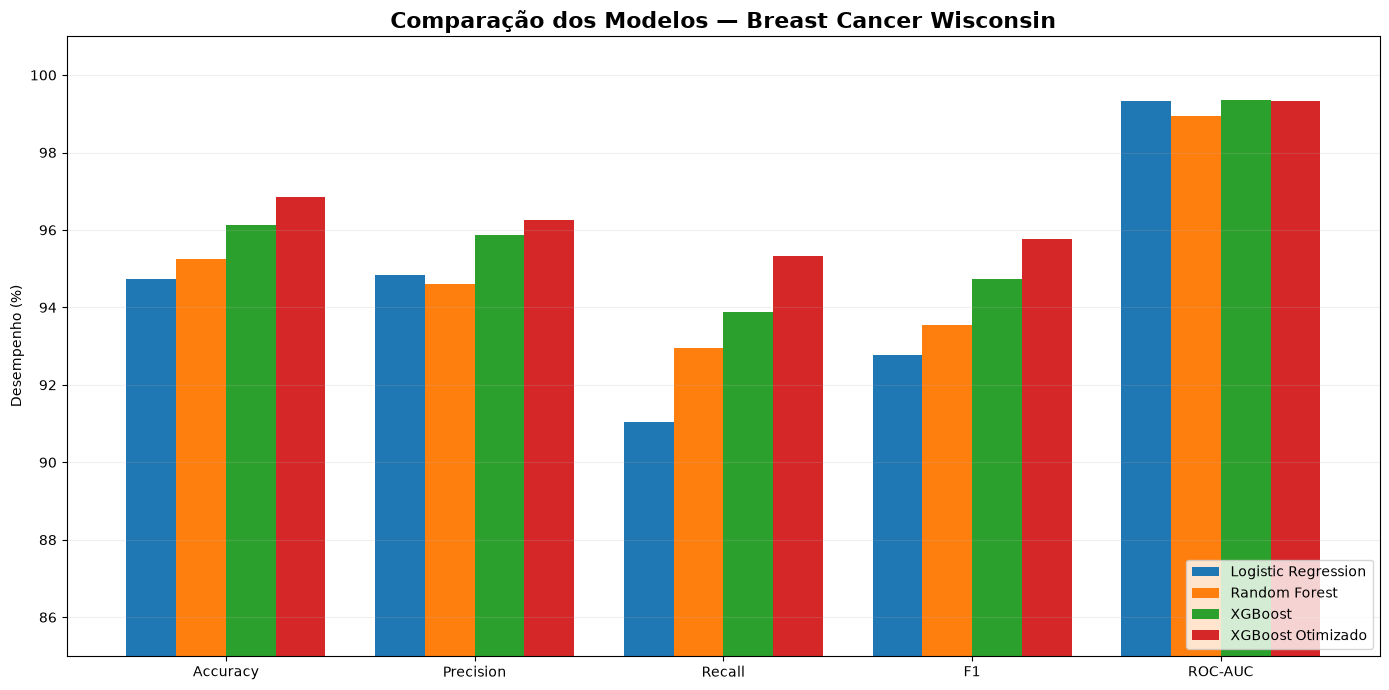

In [50]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# RESULTADOS DA CROSS-VALIDATION
# ============================================================

resultados = pd.DataFrame({
    "Modelo": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost",
        "XGBoost Otimizado"
    ],

    "Accuracy": [
        0.9473,
        0.9526,
        0.9613,
        0.9684
    ],

    "Precision": [
        0.9484,
        0.9461,
        0.9588,
        0.9625
    ],

    "Recall": [
        0.9105,
        0.9295,
        0.9389,
        0.9532
    ],

    "F1": [
        0.9278,
        0.9355,
        0.9473,
        0.9577
    ],

    "ROC-AUC": [
        0.9932,
        0.9895,
        0.9936,
        0.9934
    ]
})

# ============================================================
# TRANSFORMAR PARA PORCENTAGEM
# ============================================================

metricas = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC"
]

resultados[metricas] = resultados[metricas] * 100

# ============================================================
# GRÁFICO
# ============================================================

x = np.arange(len(metricas))

largura = 0.20

fig, ax = plt.subplots(figsize=(14, 7))

for i, modelo in enumerate(resultados["Modelo"]):

    valores = resultados.loc[
        i,
        metricas
    ].values

    ax.bar(
        x + (i - 1.5) * largura,
        valores,
        largura,
        label=modelo
    )

# ============================================================
# CONFIGURAÇÕES
# ============================================================

ax.set_title(
    "Comparação dos Modelos — Breast Cancer Wisconsin",
    fontsize=16,
    fontweight="bold"
)

ax.set_ylabel(
    "Desempenho (%)"
)

ax.set_xticks(x)

ax.set_xticklabels(
    metricas
)

ax.set_ylim(
    85,
    101
)

ax.legend(
    loc="lower right"
)

ax.grid(
    axis="y",
    alpha=0.2
)

plt.tight_layout()

plt.show()

# RECALL DAS CLASSES

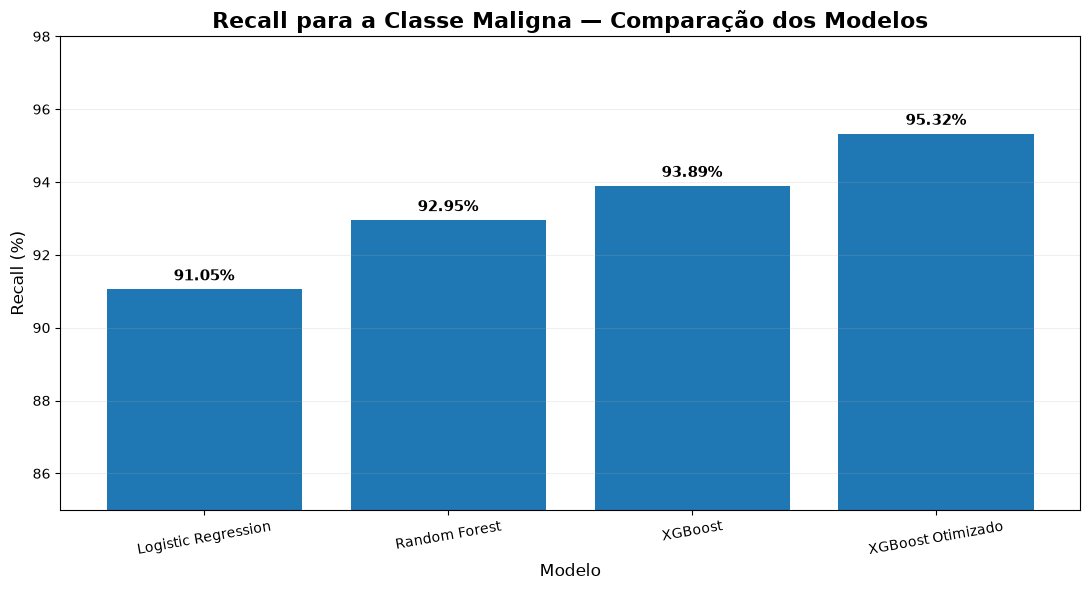

In [52]:
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# RECALL DA CLASSE MALIGNA (1)
# ============================================================

modelos = [
    "Logistic Regression",
    "Random Forest",
    "XGBoost",
    "XGBoost Otimizado"
]

recall = [
    91.05,
    92.95,
    93.89,
    95.32
]

# ============================================================
# GRÁFICO
# ============================================================

fig, ax = plt.subplots(figsize=(11, 6))

barras = ax.bar(
    modelos,
    recall
)

# ============================================================
# VALORES NAS BARRAS
# ============================================================

for barra, valor in zip(barras, recall):

    ax.text(
        barra.get_x() + barra.get_width() / 2,
        valor + 0.15,
        f"{valor:.2f}%",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

# ============================================================
# CONFIGURAÇÕES
# ============================================================

ax.set_title(
    "Recall para a Classe Maligna — Comparação dos Modelos",
    fontsize=16,
    fontweight="bold"
)

ax.set_ylabel(
    "Recall (%)",
    fontsize=12
)

ax.set_xlabel(
    "Modelo",
    fontsize=12
)

# Começar o eixo em 85 para destacar melhor as diferenças
ax.set_ylim(85, 98)

ax.grid(
    axis="y",
    alpha=0.2
)

plt.xticks(
    rotation=10
)

plt.tight_layout()

plt.show()

# GRAFICO DO SHAP

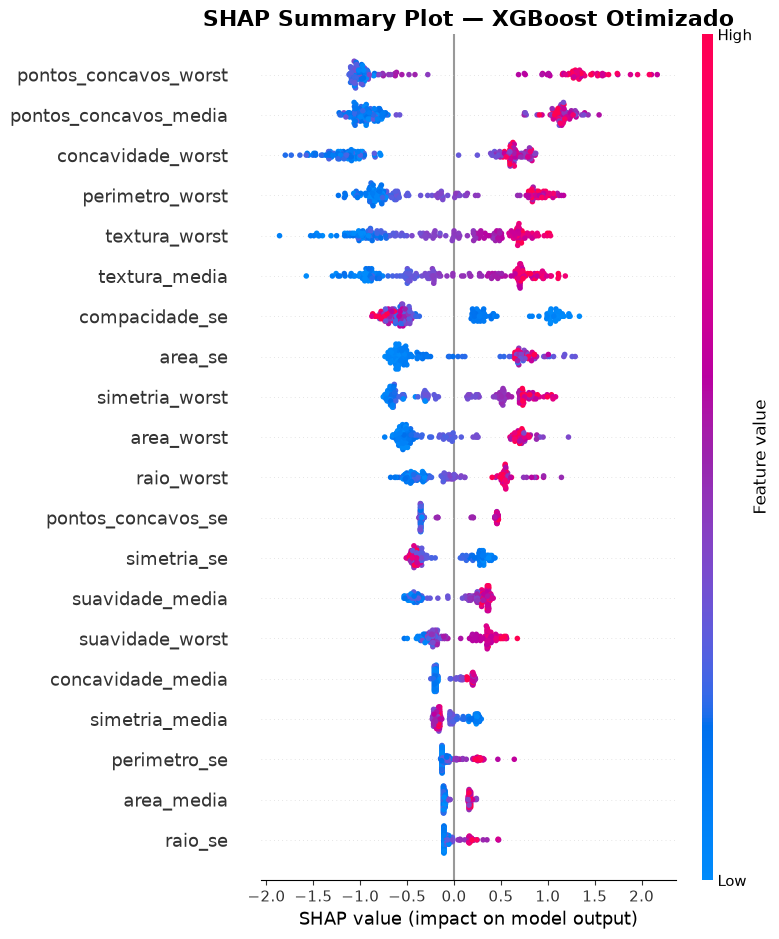

In [53]:
import shap
import matplotlib.pyplot as plt

# Criar o explainer
explainer = shap.TreeExplainer(modelo_xgb_otimizado)

# Calcular os valores SHAP
shap_values = explainer.shap_values(X_test)

# Summary Plot
plt.figure(figsize=(10, 7))

shap.summary_plot(
    shap_values,
    X_test,
    show=False
)

plt.title(
    "SHAP Summary Plot — XGBoost Otimizado",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# MATRIZ DE CONFUSAO

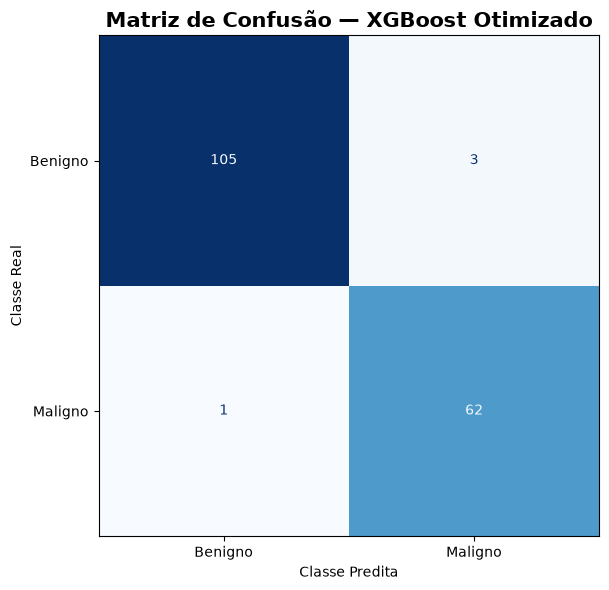

In [54]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Fazer previsões
y_pred_xgb = modelo_xgb_otimizado.predict(X_test)

# Matriz de confusão
cm = confusion_matrix(y_test, y_pred_xgb)

# Plot
fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benigno", "Maligno"]
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title(
    "Matriz de Confusão — XGBoost Otimizado",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Classe Predita")
plt.ylabel("Classe Real")

plt.tight_layout()
plt.show()